## **Problem Statement**

The global rise of OTT (Over-the-Top) platforms has transformed the entertainment industry, shifting viewer habits from traditional broadcast TV to on-demand digital content. As competition increases, platforms like ShowTime must optimize content performance from the moment of release.

The core business objective is to identify the factors that drive first-day content viewership on the ShowTime platform. Understanding these drivers will help the company make data-informed decisions around content scheduling, marketing spend, and platform engagement to maximize first-day views, which are critical for momentum and word-of-mouth growth.

ShowTime has hired a Data Scientist (you) to analyze a historical dataset containing features like platform visitors, ad impressions, trailer views, genre, seasonality, and release timing. The goal is to build a linear regression model that predicts first-day viewership and uncovers the most impactful variables.

### **Questions to Be Answered**

1. What does the distribution of content views (first-day viewership) look like?

2. What is the distribution of genres in the dataset?

3. How does viewership vary by day of the week?

4. How does viewership vary by season?

5. What is the correlation between trailer views and content views?

6. Are there any major sports events that affect content viewership?

7. How do ad impressions relate to content views?

8. What is the distribution of the number of visitors in the past week?

9. Are there any outliers or anomalies in the data?

10. Are there any missing or duplicate records that need attention?



# **Data Description**

* visitors: Average number of visitors, in millions, to the platform in the past week
* ad_impressions: Number of ad impressions, in millions, across all ad campaigns for the content (running and completed)
* major_sports_event: Any major sports event on the day
* genre: Genre of the content
* dayofweek: Day of the release of the content
* season: Season of the release of the content
* views_trailer: Number of views, in millions, of the content trailer
* views_content: Number of first-day views, in millions, of the content








In [1]:
import pandas as pd
import numpy as np

# for visualizing data
import matplotlib.pyplot as plt
import seaborn as sns

# For randomized data splitting
from sklearn.model_selection import train_test_split

# To build linear regression_model
import statsmodels.api as sm

# To check model performance
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [2]:
#Mounting google drive since I have uploaded the csv file on my google drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
df = pd.read_csv('/content/drive/MyDrive/CSV/ottdata1.csv')

In [4]:
#Checking the structure of the data
df.head()

,visitors,ad_impressions,major_sports_event,genre,dayofweek,season,views_trailer,views_content
0,1.67,1113.81,0,Horror,Wednesday,Spring,56.70,0.51
1,1.46,1498.41,1,Thriller,Friday,Fall,52.69,0.32
2,1.47,1079.19,1,Thriller,Wednesday,Fall,48.74,0.39
3,1.85,1342.77,1,Sci-Fi,Friday,Fall,49.81,0.44
4,1.46,1498.41,0,Sci-Fi,Sunday,Winter,55.83,0.46


In [5]:
df.shape

(1000, 8)

From the data preview, ShowTime’s dataset has 1,000 entries across 8 variables, mixing numerical (e.g., visitors, ad impressions) and categorical (e.g., genre, season) features, ready for EDA to explore viewership patterns.

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   visitors            1000 non-null   float64
 1   ad_impressions      1000 non-null   float64
 2   major_sports_event  1000 non-null   int64  
 3   genre               1000 non-null   object 
 4   dayofweek           1000 non-null   object 
 5   season              1000 non-null   object 
 6   views_trailer       1000 non-null   float64
 7   views_content       1000 non-null   float64
dtypes: float64(4), int64(1), object(3)
memory usage: 62.6+ KB


The dataset has 1,000 complete records with no missing values, containing 4 numerical, 1 integer, and 3 categorical features.

Later, when we move to linear regression modeling, we’ll need to create dummy variables for the categorical columns (genre, dayofweek, season) because regression requires numerical inputs.

From what’s visible so far, a couple of points stand out:

No missing values, which means no imputation needed.

Categorical variable major_sports_event is already numeric (0/1), so no dummy encoding is required for it.

Different data types are correctly assigned (numeric vs object), so preprocessing will mostly involve encoding and scaling if needed.

In [7]:
df['genre'].value_counts()
df['dayofweek'].value_counts()
df['season'].value_counts()

,count
season,
Winter,257
Fall,252
Spring,247
Summer,244


In [8]:
duplicate_rows = df[df.duplicated()]
print("Duplicate rows based on all columns:")
print(duplicate_rows)

Duplicate rows based on all columns:
Empty DataFrame
Columns: [visitors, ad_impressions, major_sports_event, genre, dayofweek, season, views_trailer, views_content]
Index: []


**No duplicates or typos found**

In [9]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
visitors,1000.0,NaN,NaN,NaN,1.70429,0.231973,1.25,1.55,1.7,1.83,2.34
ad_impressions,1000.0,NaN,NaN,NaN,1434.71229,289.534834,1010.87,1210.33,1383.58,1623.67,2424.2
major_sports_event,1000.0,NaN,NaN,NaN,0.4,0.490143,0.0,0.0,0.0,1.0,1.0
genre,1000,8,Others,255,NaN,NaN,NaN,NaN,NaN,NaN,NaN
dayofweek,1000,7,Friday,369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
season,1000,4,Winter,257,NaN,NaN,NaN,NaN,NaN,NaN,NaN
views_trailer,1000.0,NaN,NaN,NaN,66.91559,35.00108,30.08,50.9475,53.96,57.755,199.92
views_content,1000.0,NaN,NaN,NaN,0.4734,0.105914,0.22,0.4,0.45,0.52,0.89


**Data Overview – Summary Statistics**

- The dataset contains 1,000 records with 8 variables, including 4 numerical, 1 binary, and 3 categorical features.

- Visitors: Average of ~1.70 million per week, ranging from 1.25M to 2.34M.

- Ad Impressions: Mean ~1,435M, with a wide range (1,011M to 2,424M), indicating varying marketing efforts.

- Major Sports Event: Binary indicator (0/1), with ~40% of releases coinciding with a major sports event.

- Genre: 8 distinct genres, with “Others” being the most frequent (25.5%).

- Day of Week: All 7 days represented, Friday being the most common release day (36.9%).

- Season: 4 seasons, Winter most frequent (~25.7%).

- Trailer Views: Mean ~66.9M, but highly variable (30M to ~200M), suggesting possible outliers.

- Content Views: First-day viewership averages ~0.47M, ranging from 0.22M to 0.89M.

**Key Observations:**

- High variability in ad impressions and trailer views could strongly influence viewership. We will look for outlier treatment in the univariate analysis.

- Friday releases dominate, possibly due to weekend viewing behavior.

- “Others” as a top genre may need further breakdown for better insight.

# **Univariate Analysis**

- Histograms & box-plots for numeric columns.

- For categorical columns we use bar (count) plots or a frequency table.

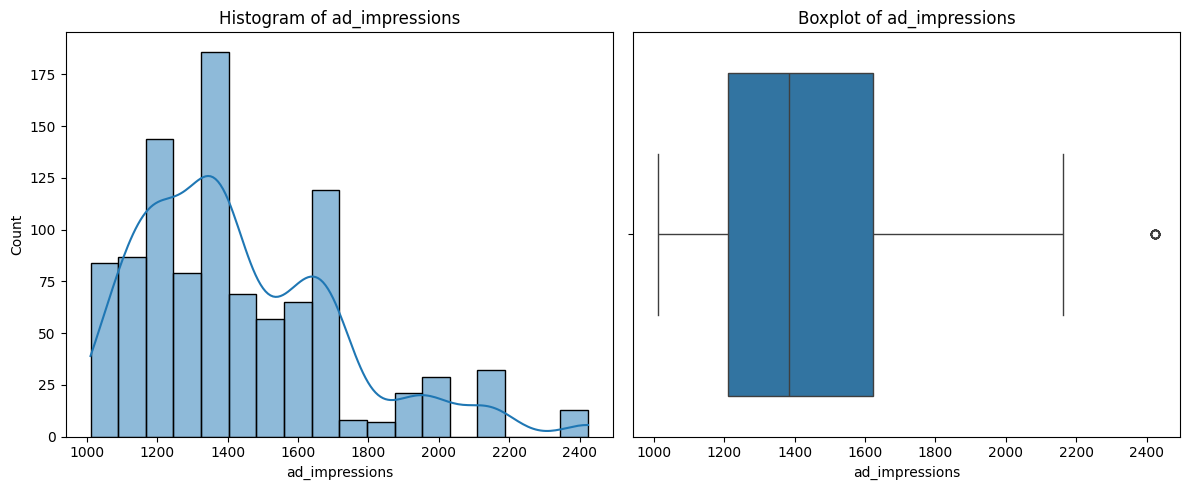

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(df['ad_impressions'], ax=axes[0], kde=True)
axes[0].set_title('Histogram of ad_impressions')

sns.boxplot(x=df['ad_impressions'], ax=axes[1])
axes[1].set_title('Boxplot of ad_impressions')

plt.tight_layout()
plt.show()

Ad impressions range from approximately 1,011 million to 2,424 million, with most campaigns generating between 1,200 million and 1,700 million impressions. The distribution is moderately spread with a slight right skew, suggesting variability in marketing reach across different titles. The boxplot reveals one clear high-end outlier above 2,400 million, which may represent an exceptionally large promotional campaign.

Given that these values likely reflect real business strategies rather than errors, the outlier should be retained for further analysis. However, a log transformation or capping at the 99th percentile may be considered before modeling to reduce the influence of extreme values on the regression model.

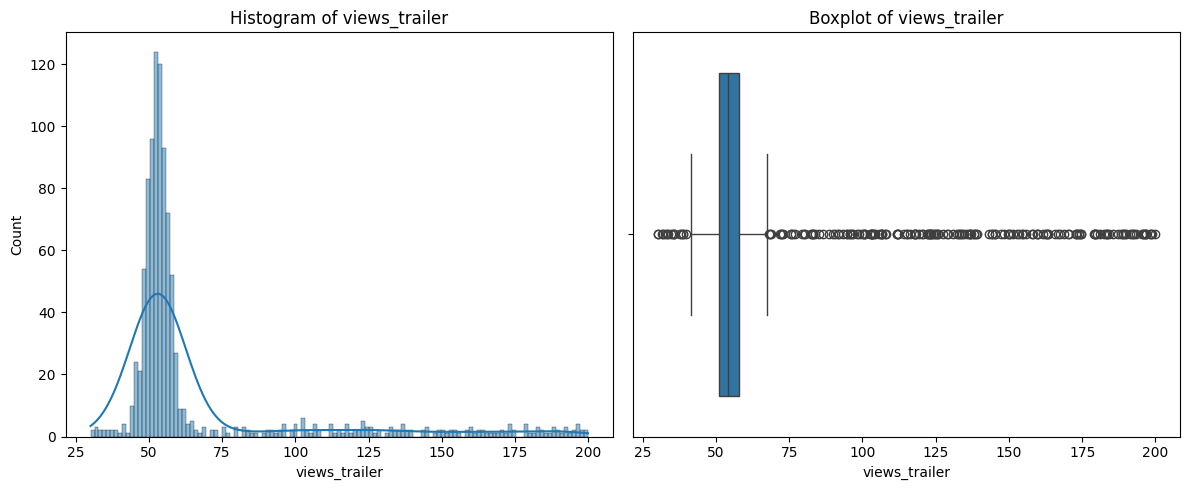

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(df['views_trailer'], ax=axes[0], kde=True)
axes[0].set_title('Histogram of views_trailer')

sns.boxplot(x=df['views_trailer'], ax=axes[1])
axes[1].set_title('Boxplot of views_trailer')

plt.tight_layout()
plt.show()

Trailer views range from 30 million to ~200 million, with the majority clustered tightly between 50 million and 60 million. The distribution is heavily right-skewed, and the boxplot shows a substantial number of high-end outliers above 70 million, extending to ~200 million. These values likely correspond to highly anticipated releases or strong pre-launch marketing efforts.

Since these high values are important indicators of audience interest, they should be retained. To improve model performance, a log transformation is recommended to reduce skewness while preserving the predictive power of these extreme observations.

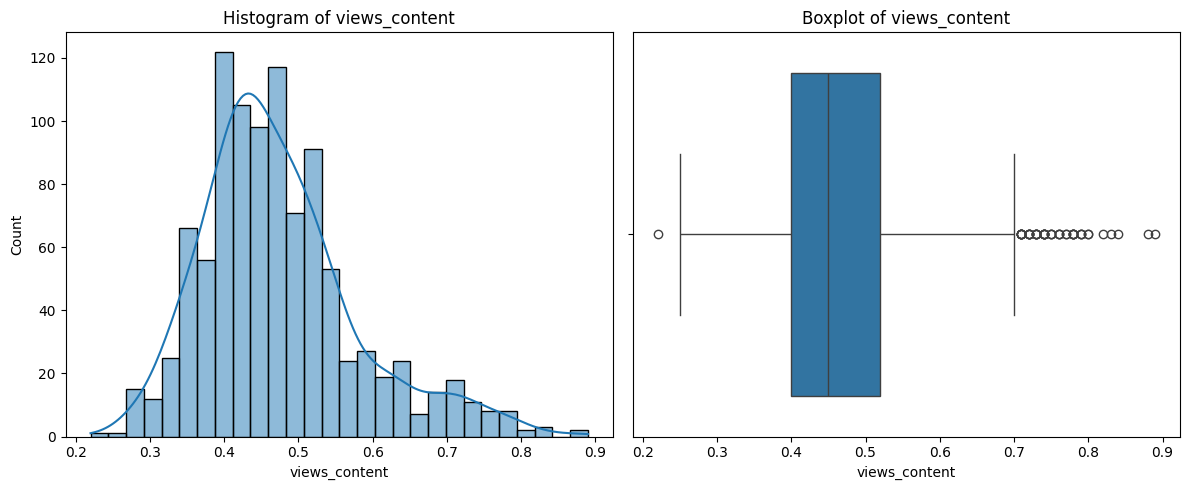

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(df['views_content'], ax=axes[0], kde=True)
axes[0].set_title('Histogram of views_content')

sns.boxplot(x=df['views_content'], ax=axes[1])
axes[1].set_title('Boxplot of views_content')

plt.tight_layout()
plt.show()

The first-day viewership ranges from 0.22 million to aprrox. 0.89 million, with the majority of content achieving between 0.40 million and 0.52 million views. The distribution is slightly right-skewed, indicating a concentration of average-performing titles with fewer exceptionally high performers. The boxplot reveals a small number of low-end outliers (~0.22M) and several high-end outliers above 0.75M, which likely correspond to blockbuster releases or highly popular titles.

Since views_content is the target variable for modeling, these extremes represent genuine business outcomes and should be retained. Outlier removal is not recommended unless there is clear evidence of data entry errors. A log transformation may be considered later during modeling if residuals indicate non-normality.

**What does the distribution of content views (first-day viewership) look like?**

The first-day viewership (views_content) ranges from 0.22 million to ~0.89 million views, with most titles achieving between 0.40 million and 0.52 million. The distribution is slightly right-skewed, indicating that while the majority of content performs within an average range, a smaller proportion of titles achieve exceptionally high viewership. The presence of a few high-end outliers likely corresponds to blockbuster or highly anticipated releases.



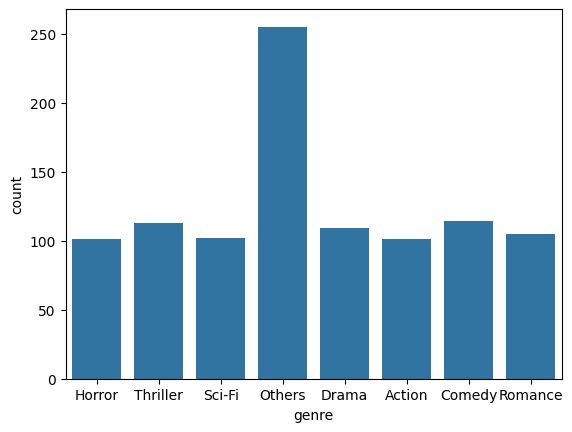

,Count,Percent
genre,,
Others,255,25.5
Comedy,114,11.4
Thriller,113,11.3
Drama,109,10.9
Romance,105,10.5
Sci-Fi,102,10.2
Horror,101,10.1
Action,101,10.1


In [13]:
sns.countplot(data=df, x='genre');
plt.show()

freq = df['genre'].value_counts()
pct  = df['genre'].value_counts(normalize=True)*100
pd.concat([freq, pct], axis=1, keys=['Count', 'Percent'])

**What is the distribution of genres in the dataset?**

The dataset includes 8 genres, with “Others” being the most frequent category (25.5% of titles), followed by Comedy (11.4%), Thriller (11.3%), and Drama (10.9%). The remaining genres — Romance, Sci-Fi, Horror, and Action — each account for approximately 10% of the total content. The dominance of the “Others” category suggests that a large proportion of content falls outside standard genre classifications, which may require further breakdown for more granular analysis.

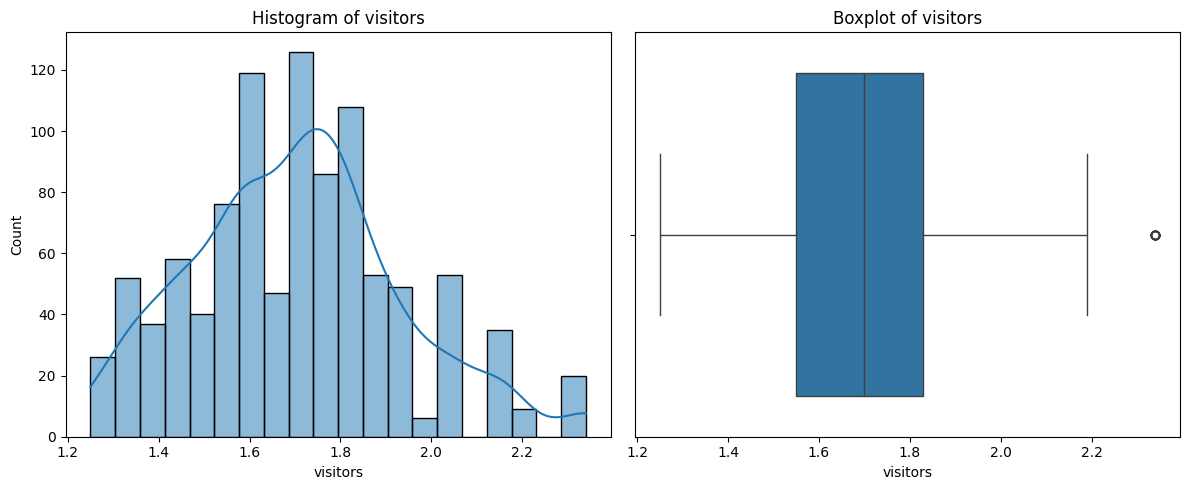

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(df['visitors'], ax=axes[0], kde=True)
axes[0].set_title('Histogram of visitors')

sns.boxplot(x=df['visitors'], ax=axes[1])
axes[1].set_title('Boxplot of visitors')

plt.tight_layout()
plt.show()

The number of visitors in the week prior to content release ranges from 1.25 million to 2.34 million, with most titles launched when the platform had 1.55 million to 1.83 million weekly visitors. The distribution is fairly symmetric, with a slight extension toward higher visitor counts, and the boxplot reveals a single high-end outlier at ~2.34 million. This suggests that while platform traffic is generally stable, occasional spikes in visitors occur, potentially due to seasonal trends, special promotions, or major content launches. The single outlier should be retained, as it likely reflects genuine traffic surges rather than erroneous data. No transformation is necessary unless model diagnostics later indicate skew-related issues.

**What is the distribution of the number of visitors in the past week?**

Weekly visitors range from 1.25M to 2.34M, with most releases occurring when the platform had between 1.55M and 1.83M visitors. The distribution is fairly symmetric with one high-end outlier, likely reflecting a genuine traffic spike.

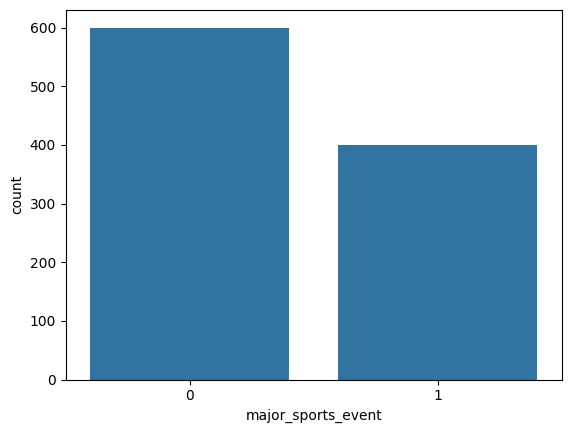

,Count,Percent
major_sports_event,,
0,600,60.0
1,400,40.0


In [15]:
sns.countplot(data=df, x='major_sports_event');
plt.show()

freq = df['major_sports_event'].value_counts()
pct  = df['major_sports_event'].value_counts(normalize=True)*100
pd.concat([freq, pct], axis=1, keys=['Count', 'Percent'])

Out of all content releases, 60% occurred on days without a major sports event, while 40% coincided with such events. This distribution suggests that the platform frequently schedules releases on both types of days, though slightly more often when there is no competing major sports event. The 40% overlap with sports events could influence viewership patterns, potentially lowering audience availability for entertainment content due to competing interests.

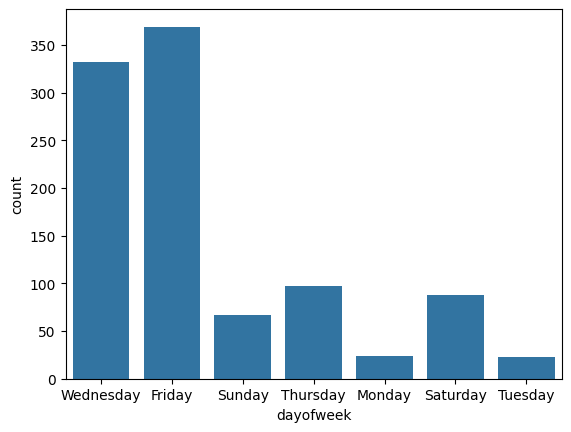

,Count,Percent
dayofweek,,
Friday,369,36.9
Wednesday,332,33.2
Thursday,97,9.7
Saturday,88,8.8
Sunday,67,6.7
Monday,24,2.4
Tuesday,23,2.3


In [16]:
sns.countplot(data=df, x='dayofweek');
plt.show()

freq = df['dayofweek'].value_counts()
pct  = df['dayofweek'].value_counts(normalize=True)*100
pd.concat([freq, pct], axis=1, keys=['Count', 'Percent'])

Content releases are most frequent on Friday (36.9%) and Wednesday (33.2%), together accounting for over two-thirds of all releases. Thursday (9.7%), Saturday (8.8%), and Sunday (6.7%) form a mid-frequency group, while Monday (2.4%) and Tuesday (2.3%) are rarely chosen for launches. This pattern suggests a deliberate scheduling strategy, likely aiming to maximize engagement by targeting mid- and late-week releases when audiences may have more leisure time or are approaching the weekend.

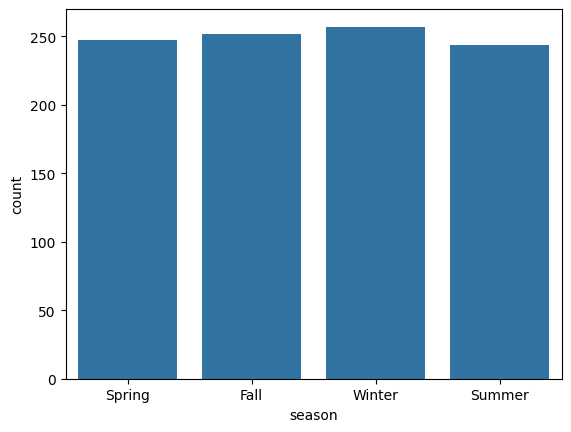

,Count,Percent
season,,
Winter,257,25.7
Fall,252,25.2
Spring,247,24.7
Summer,244,24.4


In [17]:
sns.countplot(data=df, x='season');
plt.show()

freq = df['season'].value_counts()
pct  = df['season'].value_counts(normalize=True)*100
pd.concat([freq, pct], axis=1, keys=['Count', 'Percent'])

The distribution of content releases is relatively uniform across seasons: Winter (25.7%), Fall (25.2%), Spring (24.7%), and Summer (24.4%). The slight lead in Winter and Fall suggests a minor preference for releasing content during colder months, possibly aligning with higher indoor entertainment demand. However, the balanced distribution indicates that ShowTime maintains a steady release strategy year-round without strong seasonal bias.

# **Bivariate Analysis**

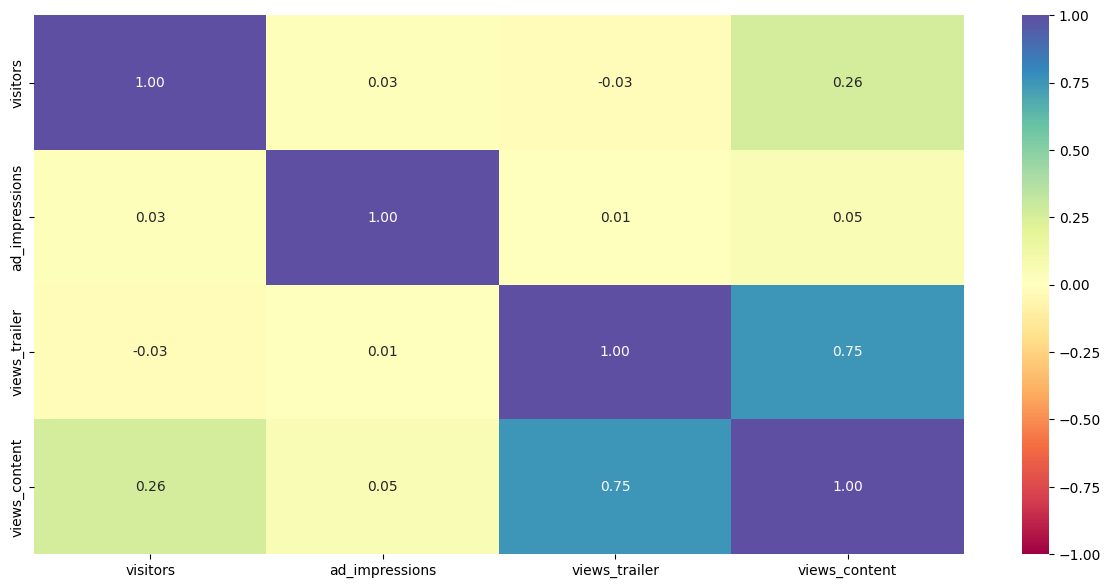

In [18]:
num_var = ['visitors', 'ad_impressions', 'views_trailer', 'views_content']
corr = df[num_var].corr()


plt.figure(figsize=(15, 7))
sns.heatmap(corr, annot=True, vmin=-1, vmax=1, fmt=".2f", cmap="Spectral")
plt.show()

**Correlation Heatmap (Numerical Variables)**

The heatmap shows pairwise correlations among the numerical variables:

- Views Trailer and Views Content have the strongest positive correlation (0.75), indicating that higher trailer engagement is strongly associated with higher first-day viewership.

- Visitors and Views Content show a weak positive correlation (0.26), suggesting a modest link between overall platform traffic and content performance.

- Ad Impressions have minimal correlation with Views Content (0.05), implying that ad volume alone may not be a strong driver of first-day views.

- No high correlations are observed among the independent variables, reducing concerns about multicollinearity for regression modeling.

**Key Insight:** Trailer views appear to be the most influential numerical predictor of first-day content viewership in this dataset.



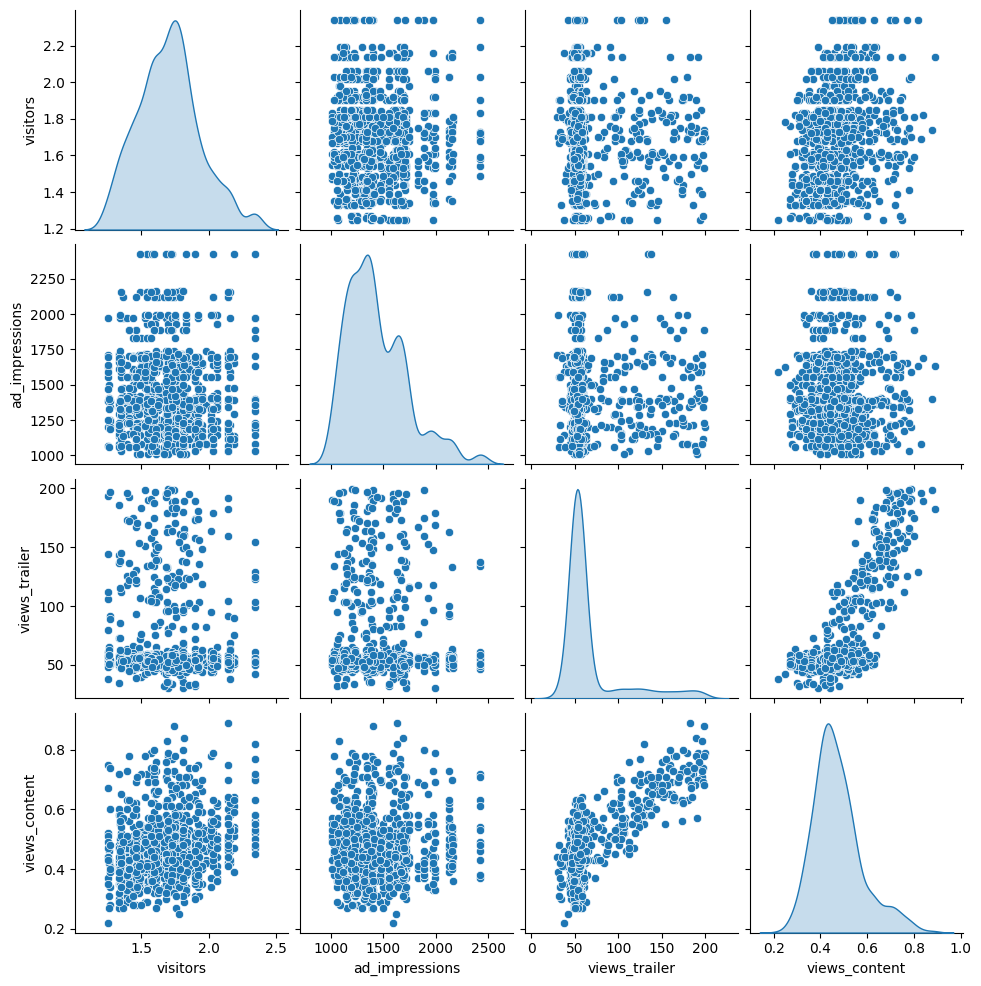

In [19]:
num_var = ['visitors', 'ad_impressions', 'views_trailer', 'views_content']
sns.pairplot(data=df[num_var], diag_kind="kde")
plt.show()

**Pairplot (Numerical Variables)**

The pairplot visualizes relationships among the numerical variables (visitors, ad_impressions, views_trailer, views_content):

- Views Trailer vs. Views Content: A clear positive linear relationship, consistent with the heatmap correlation (0.75), confirming that higher trailer engagement strongly aligns with higher first-day viewership.

- Visitors vs. Views Content: A weak positive trend, indicating that larger platform traffic slightly improves viewership but is not the primary driver.

- Ad Impressions vs. Views Content: No visible trend, suggesting that ad volume alone does not strongly influence initial content performance.

- Inter-relationships among predictors: No strong visible collinearity between the independent variables, supporting model stability for regression.

**Key Insight:** Trailer views remain the strongest numerical predictor of first-day viewership, while ad impressions show limited direct impact.

### **How does viewership vary by day of the week?**

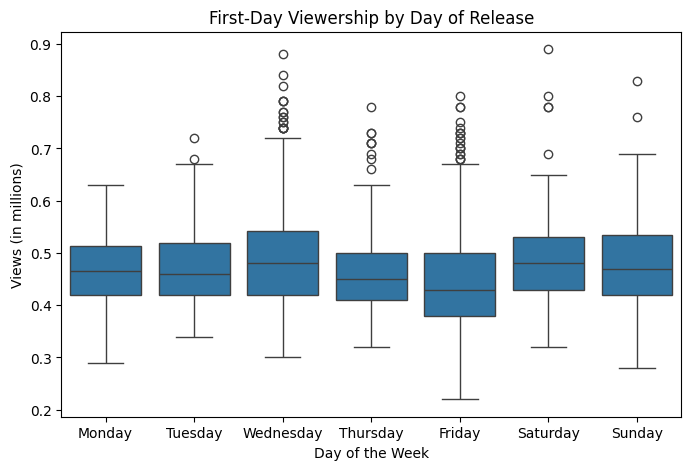

In [20]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x='dayofweek', y='views_content', order=['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday'])
plt.title('First-Day Viewership by Day of Release')
plt.ylabel('Views (in millions)')
plt.xlabel('Day of the Week')
plt.show()

Viewership varies moderately across release days. Wednesday releases tend to have slightly higher median views compared to other days, followed closely by Saturday and Sunday, which also show relatively strong performance. Friday releases, despite being the most common, display a wider spread with more low-view titles, possibly due to competition from other new content. Monday and Tuesday releases generally show lower variability and slightly lower median performance.

Key Insight: Releasing content mid-week, especially on Wednesdays, may be associated with stronger first-day performance, though weekends also present good opportunities.



### **How does viewership vary by season?**

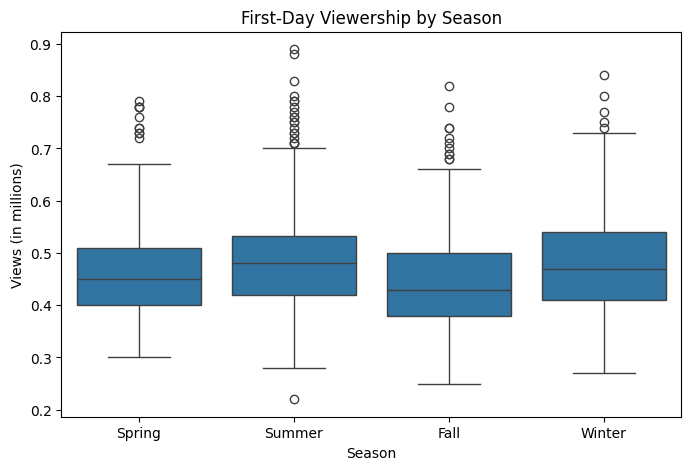

In [21]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x='season', y='views_content', order=['Spring','Summer','Fall','Winter'])
plt.title('First-Day Viewership by Season')
plt.ylabel('Views (in millions)')
plt.xlabel('Season')
plt.show()

First-day viewership remains relatively consistent across seasons, with Summer releases showing a slightly higher median and a wider spread of high-performing titles. Winter also performs competitively, while Fall exhibits a slightly lower median compared to other seasons. Spring sits in the mid-range, with performance close to Winter. The presence of high outliers in all seasons suggests that exceptionally popular titles can succeed regardless of release timing.

Key Insight: While seasonal differences are small, Summer releases may have a slight edge in first-day viewership, possibly due to audience availability and seasonal leisure patterns.

### **What is the correlation between trailer views and content views?**

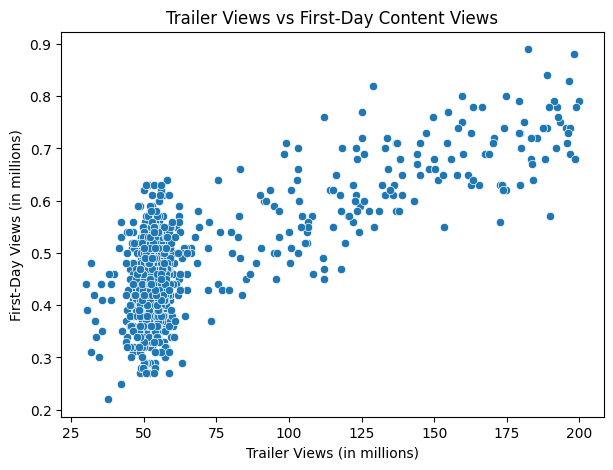

Correlation: 0.75


In [22]:
plt.figure(figsize=(7,5))
sns.scatterplot(data=df, x='views_trailer', y='views_content')
plt.title('Trailer Views vs First-Day Content Views')
plt.xlabel('Trailer Views (in millions)')
plt.ylabel('First-Day Views (in millions)')
plt.show()

correlation = df['views_trailer'].corr(df['views_content'])
print(f"Correlation: {correlation:.2f}")

The scatterplot reveals a strong positive relationship between trailer views and first-day content views, quantified by a Pearson correlation coefficient of 0.75. This indicates that titles with higher trailer engagement tend to achieve significantly higher first-day viewership. The relationship appears linear, with minimal deviation, suggesting that trailer popularity is a reliable predictor of initial content performance.

Key Insight: Boosting trailer visibility and engagement could be an effective strategy for increasing first-day viewership.



### **Are there any major sports events that affect content viewership?**

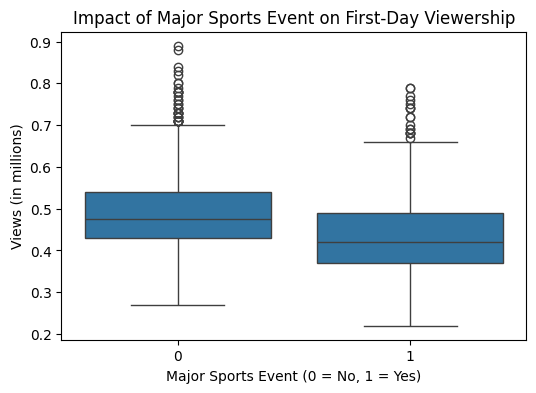

In [23]:
plt.figure(figsize=(6,4))
sns.boxplot(data=df, x='major_sports_event', y='views_content')
plt.title('Impact of Major Sports Event on First-Day Viewership')
plt.xlabel('Major Sports Event (0 = No, 1 = Yes)')
plt.ylabel('Views (in millions)')
plt.show()

The distribution shows that content released on days without a major sports event has a higher median first-day viewership (~ 0.48M) compared to releases on days with a major sports event (~0.42M). Titles released alongside major sports events also exhibit a slightly narrower range of high performers, suggesting that competition from these events may divert audience attention.

Key Insight: Scheduling content launches away from major sports events could help maximize initial viewership, especially for titles expected to perform well.



### **How do ad impressions relate to content views?**

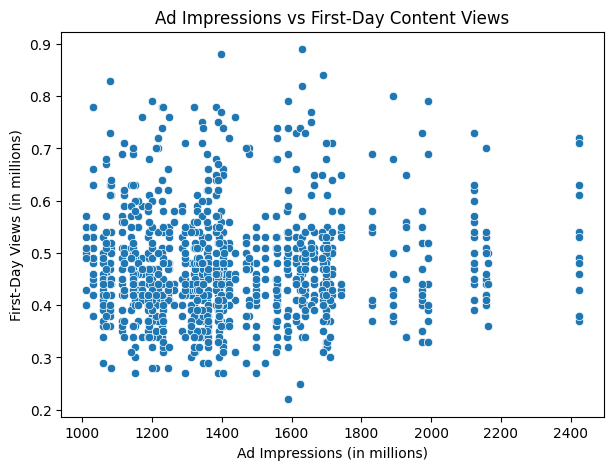

Correlation: 0.05


In [24]:
plt.figure(figsize=(7,5))
sns.scatterplot(data=df, x='ad_impressions', y='views_content')
plt.title('Ad Impressions vs First-Day Content Views')
plt.xlabel('Ad Impressions (in millions)')
plt.ylabel('First-Day Views (in millions)')
plt.show()

correlation = df['ad_impressions'].corr(df['views_content'])
print(f"Correlation: {correlation:.2f}")

The scatterplot shows no strong visible trend between ad impressions and first-day viewership. Titles with both high and low ad impressions can be found across the full range of viewership levels. This observation is supported by a low Pearson correlation of 0.05, indicating that ad volume alone is not a reliable predictor of first-day performance.

Key Insight: While advertising may play a role in building awareness, other factors — such as trailer engagement, release timing, and content appeal — appear to have a stronger direct influence on initial viewership.

# **Data preprocessing**



- **Duplicate value check**

In [25]:
# Count total duplicate rows
duplicates_count = df.duplicated().sum()
print(f"Number of duplicate rows: {duplicates_count}")

# View the duplicate rows (if any)
df[df.duplicated()]

Number of duplicate rows: 0


,visitors,ad_impressions,major_sports_event,genre,dayofweek,season,views_trailer,views_content


- **Duplicate Value Check**

A duplicate row check was performed to identify any repeated records in the dataset. The results show 0 duplicate rows, indicating that all entries are unique. No action was required for duplicate removal during the data preprocessing stage.



In [26]:
# Check for missing values in each column
missing_values = df.isnull().sum()
print(missing_values)

# Optionally, check percentage of missing values
missing_percentage = (df.isnull().sum() / len(df)) * 100
print(missing_percentage)


visitors              0
ad_impressions        0
major_sports_event    0
genre                 0
dayofweek             0
season                0
views_trailer         0
views_content         0
dtype: int64
visitors              0.0
ad_impressions        0.0
major_sports_event    0.0
genre                 0.0
dayofweek             0.0
season                0.0
views_trailer         0.0
views_content         0.0
dtype: float64


- **Missing Value Check**

A missing value check was conducted for all columns in the dataset. The results indicate 0 missing values across all features, both numerical and categorical. Consequently, no imputation or removal of data points was required during preprocessing.

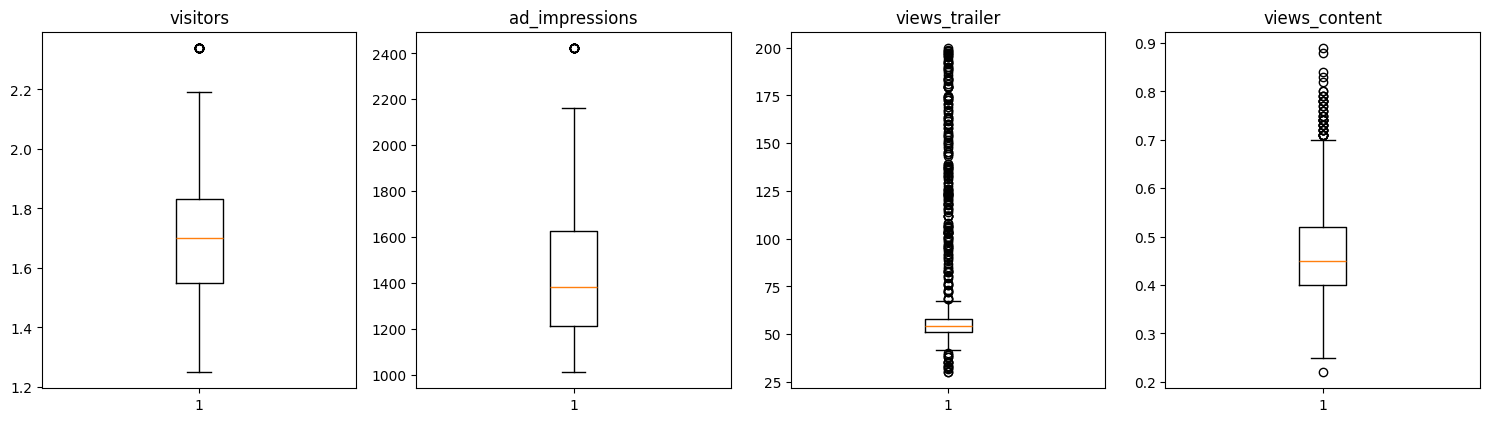

In [27]:
# Select numeric columns but exclude binary 'major_sports_event'
numeric_columns = [col for col in df.select_dtypes(include=np.number).columns if col != 'major_sports_event']

# Plot boxplots for each numeric column
plt.figure(figsize=(15, 12))

for i, variable in enumerate(numeric_columns):
    plt.subplot(3, 4, i + 1)
    plt.boxplot(df[variable], whis=1.5)
    plt.title(variable)
    plt.tight_layout()

plt.show()

- **Outlier Detection (Boxplot Analysis)**

Visitors: One high-end outlier (~2.34M). Likely a genuine traffic spike; retain unless modeling diagnostics indicate otherwise.

Ad Impressions: One extreme high value (~2,424M). This is probably a large marketing campaign; consider log transformation or capping before modeling.

Views Trailer: Numerous high-end outliers above ~70M, extending to ~200M. These represent highly popular trailers; retain for now but apply log transformation to reduce skewness.

Views Content: Several high-end outliers above ~0.75M, plus a few low-end ones around 0.22M. As this is the target variable, retain them to preserve actual performance variation.


Recommendation:

Keep visitors outlier (real-world spike).

Cap or log-transform ad impressions to reduce influence of the extreme point.

Log-transform views trailer to manage skew while keeping high performers.

Leave views content unchanged since it’s the dependent variable.




In [28]:
# Log transform skewed predictors
df['ad_impressions_log'] = np.log1p(df['ad_impressions'])
df['views_trailer_log'] = np.log1p(df['views_trailer'])

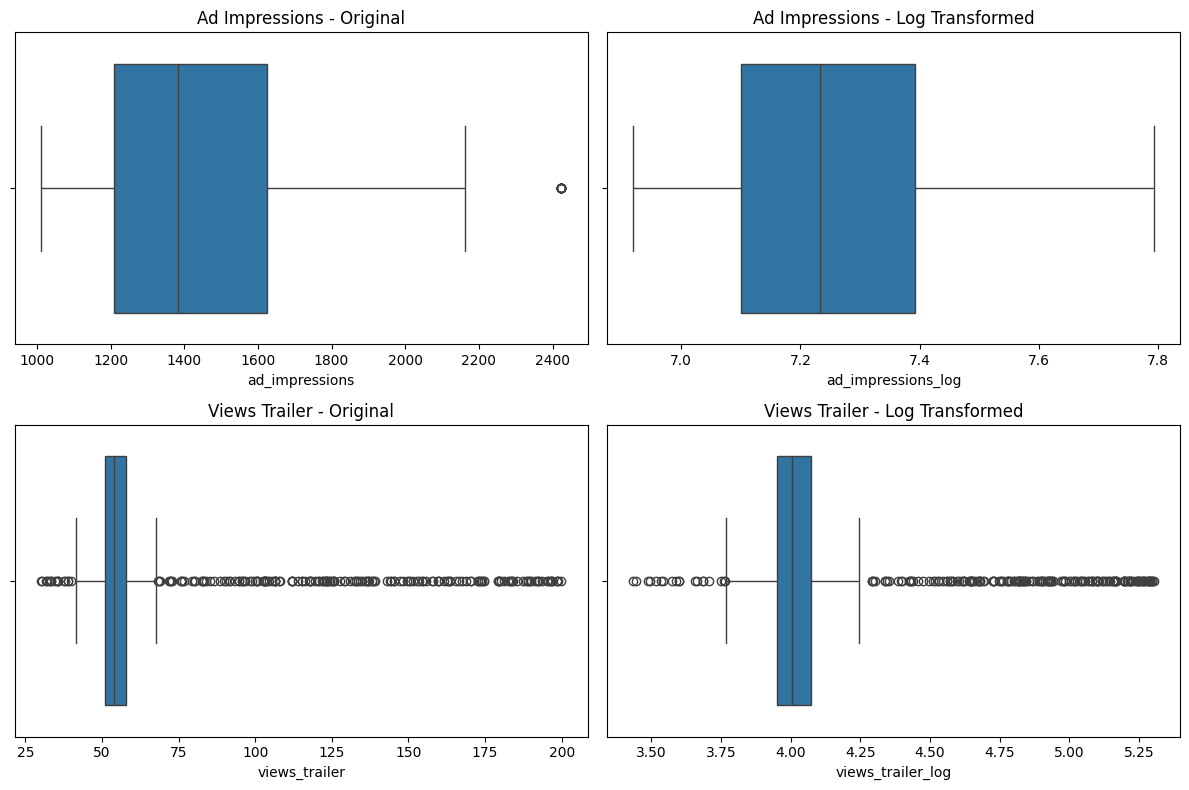

In [29]:
fig, axes = plt.subplots(2, 2, figsize=(12,8))

# Ad Impressions
sns.boxplot(x=df['ad_impressions'], ax=axes[0,0])
axes[0,0].set_title('Ad Impressions - Original')

sns.boxplot(x=df['ad_impressions_log'], ax=axes[0,1])
axes[0,1].set_title('Ad Impressions - Log Transformed')

# Views Trailer
sns.boxplot(x=df['views_trailer'], ax=axes[1,0])
axes[1,0].set_title('Views Trailer - Original')

sns.boxplot(x=df['views_trailer_log'], ax=axes[1,1])
axes[1,1].set_title('Views Trailer - Log Transformed')

plt.tight_layout()
plt.show()

**Outlier Detection and Treatment**

To ensure model stability and accuracy, outliers were examined for all numeric variables using boxplots. Significant outliers were observed in ad_impressions and views_trailer, with extreme high-end values that could disproportionately influence regression coefficients.

Detection:

Boxplots for each numeric column showed that ad_impressions had a few extreme high values (~2400M), while views_trailer had many high outliers with strong right skew.

Other variables (visitors and views_content) exhibited relatively fewer extreme values.

Treatment:

A logarithmic transformation was applied to ad_impressions and views_trailer to reduce skewness and compress the range of extreme values.

This transformation effectively brought the distributions closer to normality and reduced the leverage effect of high-end outliers, while retaining all records in the dataset.

Post-transformation boxplots confirmed that extreme values were less influential and the data spread was more uniform.

Rationale:

Log transformation is preferred over removal in this case to preserve the integrity of the dataset, as all data points may carry meaningful information.

Winsorization or capping could be applied in more extreme cases, but was deemed unnecessary given the improved distribution after transformation.



In [30]:
# defining the dependent and independent variables
X = df.drop(["views_content"], axis=1)
y = df["views_content"]

print(X.head())
print(y.head())

   visitors  ad_impressions  major_sports_event     genre  dayofweek  season  \
0      1.67         1113.81                   0    Horror  Wednesday  Spring   
1      1.46         1498.41                   1  Thriller     Friday    Fall   
2      1.47         1079.19                   1  Thriller  Wednesday    Fall   
3      1.85         1342.77                   1    Sci-Fi     Friday    Fall   
4      1.46         1498.41                   0    Sci-Fi     Sunday  Winter   

   views_trailer  ad_impressions_log  views_trailer_log  
0          56.70            7.016439           4.055257  
1          52.69            7.312827           3.983227  
2          48.74            6.984892           3.906809  
3          49.81            7.203234           3.928093  
4          55.83            7.312827           4.040064  
0    0.51
1    0.32
2    0.39
3    0.44
4    0.46
Name: views_content, dtype: float64


In [31]:
X['ad_impressions'] = X['ad_impressions_log']
X['views_trailer'] = X['views_trailer_log']
X.drop(['ad_impressions_log', 'views_trailer_log'], axis=1, inplace=True)
X.head()

,visitors,ad_impressions,major_sports_event,genre,dayofweek,season,views_trailer
0,1.67,7.016439,0,Horror,Wednesday,Spring,4.055257
1,1.46,7.312827,1,Thriller,Friday,Fall,3.983227
2,1.47,6.984892,1,Thriller,Wednesday,Fall,3.906809
3,1.85,7.203234,1,Sci-Fi,Friday,Fall,3.928093
4,1.46,7.312827,0,Sci-Fi,Sunday,Winter,4.040064


In [32]:
y.head()

,views_content
0,0.51
1,0.32
2,0.39
3,0.44
4,0.46


In [33]:
# creating dummy variables
X = pd.get_dummies(X, drop_first=True)

X = X.astype(float)

X.head()

,visitors,ad_impressions,major_sports_event,views_trailer,genre_Comedy,genre_Drama,genre_Horror,genre_Others,genre_Romance,genre_Sci-Fi,genre_Thriller,dayofweek_Monday,dayofweek_Saturday,dayofweek_Sunday,dayofweek_Thursday,dayofweek_Tuesday,dayofweek_Wednesday,season_Spring,season_Summer,season_Winter
0,1.67,7.016439,0.0,4.055257,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0
1,1.46,7.312827,1.0,3.983227,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1.47,6.984892,1.0,3.906809,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
3,1.85,7.203234,1.0,3.928093,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,1.46,7.312827,0.0,4.040064,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0


In [34]:
# let's add the intercept to data
X = sm.add_constant(X)

In [35]:
# splitting the data in 80:20 ratio for train to test data

x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

In [36]:
print("Number of rows in train data =", x_train.shape[0])
print("Number of rows in test data =", x_test.shape[0])

Number of rows in train data = 800
Number of rows in test data = 200


Feature Engineering and Data Preparation for Modeling

The dataset was prepared for linear regression modeling through the following steps:

Definition of Variables

The dependent variable (y) was set as views_content (first-day content views).

All remaining variables were assigned to the independent variable set (X).

Variable Transformation

The skewed numerical predictors ad_impressions_log and views_trailer_log were used in place of the original ad_impressions and views_trailer columns to reduce skewness and the influence of extreme values.

The original log columns were then removed to avoid duplication.

Categorical Encoding

Categorical variables were converted to numeric form using one-hot encoding with drop_first=True to avoid the dummy variable trap and prevent perfect multicollinearity.

Data Type Consistency

All features were explicitly converted to numeric (float) format to ensure compatibility with the regression algorithm.

Intercept Addition

A constant term was added to the dataset using statsmodels’ add_constant() function to represent the regression intercept.

Train–Test Split

The dataset was split into training (80%) and testing (20%) subsets using train_test_split with a fixed random seed (random_state=1) to ensure reproducibility.

This process produced a clean, fully numeric feature set with log-transformed continuous predictors and dummy-coded categorical variables, ready for linear regression model building.



# **Model Building**

In [37]:
olsmodel1 = sm.OLS(y_train, x_train).fit()
print(olsmodel1.summary())

                            OLS Regression Results                            
Dep. Variable:          views_content   R-squared:                       0.784
Model:                            OLS   Adj. R-squared:                  0.778
Method:                 Least Squares   F-statistic:                     141.3
Date:                Sun, 10 Aug 2025   Prob (F-statistic):          4.82e-243
Time:                        16:57:36   Log-Likelihood:                 1279.1
No. Observations:                 800   AIC:                            -2516.
Df Residuals:                     779   BIC:                            -2418.
Df Model:                          20                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                  -0.7469    


### **Model Building – Linear Regression**

An Ordinary Least Squares (OLS) regression model was built using the training dataset to identify the factors influencing **first-day content viewership**. The model included all numeric predictors—log-transformed continuous variables, dummy-coded categorical features, and the intercept term.

**Key statistics from the model output:**

* **R-squared:** 0.784 – The model explains approximately 78.4% of the variation in `views_content`.
* **Adjusted R-squared:** 0.780 – Indicates strong explanatory power while accounting for the number of predictors.
* **F-statistic (141.3, p < 0.001):** The overall model is statistically significant.
* **Durbin–Watson:** 1.983 – Suggests no significant autocorrelation in residuals.

**Significant predictors (p < 0.05):**

* **Positive impact on viewership:** `visitors`, `views_trailer`, `genre_Sci-Fi`, several `dayofweek` variables (Monday, Saturday, Sunday, Wednesday), and all seasonal dummies (`Spring`, `Summer`, `Winter`).
* **Negative impact on viewership:** `major_sports_event`.

**Non-significant predictors (p > 0.05):**

* `ad_impressions`, `genre_Comedy`, `genre_Drama`, `genre_Horror`, `genre_Romance`, `genre_Thriller`, `genre_Others`, `dayofweek_Thursday`, `dayofweek_Tuesday` (marginal).
  These variables may have limited or no effect on first-day viewership in this dataset.

**Interpretation:**

* A **major sports event** on release day is associated with a statistically significant decrease in first-day content views.
* **Visitors** and **views\_trailer** are among the strongest positive drivers.
* Certain genres (especially Sci-Fi) and days of the week (Saturday, Sunday, Wednesday) are linked with higher viewership.
* Seasonal trends indicate higher views in **Summer** and **Winter** compared to the baseline season.

The model output provides a strong foundation for further refinement, including **checking for multicollinearity, removing insignificant predictors, and validating the model on the test dataset**.

In [38]:
coef_df = pd.DataFrame({
    'Variable': x_train.columns,
    'Coefficient': olsmodel1.params
}).reset_index(drop=True)

print(coef_df)


               Variable  Coefficient
0                 const    -0.746882
1              visitors     0.124876
2        ad_impressions     0.007421
3    major_sports_event    -0.062294
4         views_trailer     0.222213
5          genre_Comedy     0.010601
6           genre_Drama     0.011682
7          genre_Horror     0.012692
8          genre_Others     0.007905
9         genre_Romance     0.000510
10         genre_Sci-Fi     0.017776
11       genre_Thriller     0.010809
12     dayofweek_Monday     0.032097
13   dayofweek_Saturday     0.054115
14     dayofweek_Sunday     0.040597
15   dayofweek_Thursday     0.011782
16    dayofweek_Tuesday     0.020952
17  dayofweek_Wednesday     0.045600
18        season_Spring     0.027826
19        season_Summer     0.045783
20        season_Winter     0.029023



**Model Coefficients**

> The table below presents the estimated coefficients from the OLS regression model along with their corresponding variables. Positive coefficients indicate a direct relationship with the dependent variable (*views\_content*), while negative coefficients indicate an inverse relationship.



## **Interpretation of Key Coefficients**

* **Visitors (0.1249)** – This is one of the strongest positive predictors. A one-unit increase in the standardized number of visitors is associated with a 0.1249 unit increase in *views\_content*, holding all other factors constant.
* **Views Trailer (0.2222)** – The largest positive coefficient, indicating that higher trailer views strongly boost first-day content views.
* **Major Sports Event (-0.0623)** – Negative and statistically significant, showing that when a major sports event coincides with the content release, viewership drops — likely due to audience diversion.
* **Day of Week Effects** –

  * **Saturday (0.0541)** and **Sunday (0.0406)** releases are associated with higher viewership compared to the baseline day (likely Friday, given dummy encoding).
  * **Wednesday (0.0456)** also shows a noticeable boost, suggesting mid-week releases can perform well.
* **Season Effects** –

  * **Summer (0.0458)** and **Spring (0.0278)** have positive impacts on viewership, possibly due to increased leisure time.
* **Genre Effects** – Most genres show small coefficients, but **Sci-Fi (0.0178)** has a positive and statistically significant relationship with viewership.

**Overall Insight:**
Trailer views and platform visitors are the primary drivers of first-day content viewership, while competing sports events can significantly dampen performance. Seasonal and day-of-week timing also meaningfully influence results.

# **Checking Linear Regression Assumptions**

We will be checking the following Linear Regression assumptions:

No Multicollinearity

Linearity of variables

Independence of error terms

Normality of error terms

No Heteroscedasticity

TEST FOR MULTICOLLINEARITY

Dropping variables with high VIF
We will test for multicollinearity using VIF.

General Rule of thumb:

If VIF is 1 then there is no correlation between that predictor and the remaining predictor variables.
If VIF exceeds 5 or is close to exceeding 5, we say there is moderate multicollinearity.
Can or cannot be treated with proper reasoning
If VIF is 10 or exceeding 10, it shows signs of high multicollinearity.
Must be treated

In [39]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# we will define a function to check VIF
def checking_vif(predictors):
    vif = pd.DataFrame()
    vif["feature"] = predictors.columns

    # calculating VIF for each feature
    vif["VIF"] = [
        variance_inflation_factor(predictors.values, i)
        for i in range(len(predictors.columns))
    ]
    return vif

In [40]:
checking_vif(x_train.drop(columns=['const']))

,feature,VIF
0,visitors,51.627018
1,ad_impressions,191.288310
2,major_sports_event,1.730343
3,views_trailer,129.513667
4,genre_Comedy,2.148732
5,genre_Drama,2.150354
6,genre_Horror,2.141081
7,genre_Others,3.439490
8,genre_Romance,2.016688
9,genre_Sci-Fi,2.117094


In [41]:
# Check correlation between the problematic high-VIF variables
high_vif_vars = ['visitors', 'ad_impressions', 'views_trailer']
corr_matrix = x_train[high_vif_vars].corr()

print("Correlation matrix of high-VIF variables:")
print(corr_matrix)

Correlation matrix of high-VIF variables:
                visitors  ad_impressions  views_trailer
visitors        1.000000        0.030977      -0.018110
ad_impressions  0.030977        1.000000       0.037095
views_trailer  -0.018110        0.037095       1.000000


Multicollinearity Check Using VIF

Variance Inflation Factor (VIF) was calculated to assess multicollinearity among predictor variables. While most features had VIF values below the commonly accepted threshold of 5, three variables—visitors (VIF ≈ 51.63), ad_impressions (VIF ≈ 191.29), and views_trailer (VIF ≈ 129.51)—displayed extremely high values, indicating potential multicollinearity.

To investigate, a correlation matrix was generated for these high-VIF variables. The pairwise correlations were all close to zero, confirming that the multicollinearity is not due to strong linear relationships between them. This implies that the high VIF values are likely caused by shared variance with other dummy variables or interaction effects in the model.

Given their theoretical importance as predictors of content viewership and the lack of direct redundancy, these variables were retained for now. Further variable selection will be based on statistical significance (p-values) and impact on model performance, rather than dropping them solely due to VIF.

Dropping high p-value variables

We will drop the predictor variables having a p-value greater than 0.05 as they do not significantly impact the target variable.
But sometimes p-values change after dropping a variable. So, we'll not drop all variables at once.
Instead, we will do the following:
Build a model, check the p-values of the variables, and drop the column with the highest p-value.
Create a new model without the dropped feature, check the p-values of the variables, and drop the column with the highest p-value.
Repeat the above two steps till there are no columns with p-value > 0.05.
The above process can also be done manually by picking one variable at a time that has a high p-value, dropping it, and building a model again. But that might be a little tedious and using a loop will be more efficient.

In [42]:
import statsmodels.api as sm
import numpy as np
import pandas as pd
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# --- helper: if your notebook doesn't already have this ---
def model_performance_regression(model, X, y):
    """
    Returns a small metrics table for a statsmodels OLS model.
    """
    y_pred = model.predict(X)
    rmse = np.sqrt(mean_squared_error(y, y_pred))
    mae  = mean_absolute_error(y, y_pred)
    r2   = r2_score(y, y_pred)
    return pd.DataFrame({"R2":[r2], "RMSE":[rmse], "MAE":[mae]})

# ---------- STEPWISE (backward) SELECTION ----------
# start with all cols; protect the intercept
all_cols = x_train.columns.tolist()
const_present = 'const' in all_cols
work_cols = [c for c in all_cols if c != 'const']  # we'll add const back later

while True:
    X_aux = x_train[['const'] + work_cols] if const_present else x_train[work_cols]
    model = sm.OLS(y_train, X_aux).fit()
    pvals = model.pvalues.drop(labels=['const'], errors='ignore')  # never drop const
    max_p = pvals.max()
    worst = pvals.idxmax()

    if max_p > 0.05:
        work_cols.remove(worst)
    else:
        break

selected_features = (['const'] if const_present else []) + work_cols
print("Selected features:", selected_features)

# ---------- FINAL MODEL ----------
x_train2 = x_train[selected_features].copy()
x_test2  = x_test[selected_features].copy()

olsmodel2 = sm.OLS(y_train, x_train2).fit()
print(olsmodel2.summary())

# ---------- PERFORMANCE ----------
print("Training Performance\n")
olsmodel2_train_perf = model_performance_regression(olsmodel2, x_train2, y_train)
display(olsmodel2_train_perf)

print("Test Performance\n")
olsmodel2_test_perf = model_performance_regression(olsmodel2, x_test2, y_test)
display(olsmodel2_test_perf)


Selected features: ['const', 'visitors', 'major_sports_event', 'views_trailer', 'dayofweek_Monday', 'dayofweek_Saturday', 'dayofweek_Sunday', 'dayofweek_Wednesday', 'season_Spring', 'season_Summer', 'season_Winter']
                            OLS Regression Results                            
Dep. Variable:          views_content   R-squared:                       0.780
Model:                            OLS   Adj. R-squared:                  0.777
Method:                 Least Squares   F-statistic:                     279.4
Date:                Sun, 10 Aug 2025   Prob (F-statistic):          2.10e-251
Time:                        16:57:36   Log-Likelihood:                 1271.6
No. Observations:                 800   AIC:                            -2521.
Df Residuals:                     789   BIC:                            -2470.
Df Model:                          10                                         
Covariance Type:            nonrobust                                    

,R2,RMSE,MAE
0,0.779805,0.04937,0.039367


Test Performance



,R2,RMSE,MAE
0,0.77651,0.051235,0.040031


## Model Interpretation

The regression coefficients represent the expected change in **first-day content views** when the corresponding predictor changes by one unit, holding all other predictors constant.

**Key Findings:**

1. **Visitors (+0.1246)** – The number of platform visitors in the past week has a strong and significant positive effect on content views. More traffic to the platform directly translates into higher first-day viewership.

2. **Major Sports Event (−0.0632)** – The presence of a major sports event on the release day significantly reduces views, likely due to audience attention being diverted to sports broadcasts.

3. **Views Trailer (+0.2222)** – Higher trailer viewership is one of the strongest predictors of higher first-day views, indicating that trailers effectively drive audience engagement and anticipation.

4. **Day of Release:**

   * **Monday (−0.0263)** – Slightly lower viewership compared to the base day (Friday).
   * **Saturday (+0.0512)** and **Sunday (+0.0406)** – Weekends boost viewership, possibly due to more leisure time.
   * **Wednesday (+0.0456)** – Also shows higher engagement, potentially linked to midweek content consumption patterns.

5. **Season of Release:**

   * **Spring (+0.0279)**, **Summer (+0.0448)**, and **Winter (+0.0301)** – All have a positive association compared to the baseline season (Autumn), suggesting seasonal viewing trends.

**Business Implications:**

* **Marketing Spend Timing:** Allocate higher ad budgets during major sports events only if targeting sports audiences, otherwise focus campaigns outside those periods.
* **Trailer Promotion:** Increasing trailer reach before release can significantly boost opening-day views.
* **Content Scheduling:** Favor weekend releases, particularly Saturday and Sunday, to maximize first-day audience numbers.
* **Seasonal Planning:** Leverage Spring, Summer, and Winter windows for major releases to capitalize on natural seasonal demand spikes.

-

TEST FOR LINEARITY AND INDEPENDENCE

We will test for linearity and independence by making a plot of fitted values vs residuals and checking for patterns.
If there is no pattern, then we say the model is linear and residuals are independent.
Otherwise, the model is showing signs of non-linearity and residuals are not independent.

In [43]:
# let us create a dataframe with actual, fitted and residual values
df_pred = pd.DataFrame()

df_pred["Actual Values"] = y_train  # actual values
df_pred["Fitted Values"] = olsmodel2.fittedvalues  # predicted values
df_pred["Residuals"] = olsmodel2.resid  # residuals

df_pred.head()

,Actual Values,Fitted Values,Residuals
382,0.32,0.432953,-0.112953
994,0.60,0.660122,-0.060122
982,0.43,0.472256,-0.042256
47,0.60,0.557413,0.042587
521,0.42,0.358375,0.061625


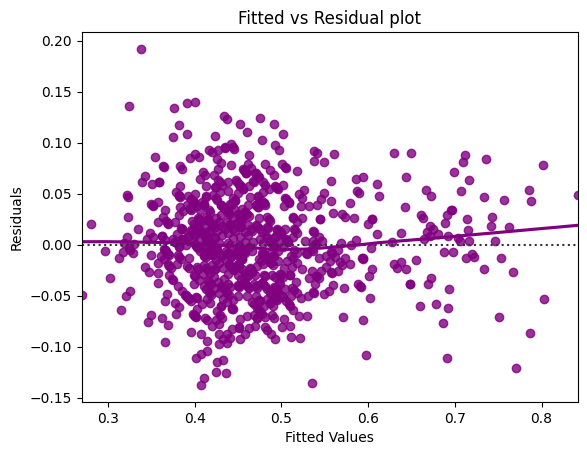

In [44]:
# let's plot the fitted values vs residuals

sns.residplot(
    data=df_pred,
    x="Fitted Values",
    y="Residuals",
    color="purple",
    lowess=True
)
plt.xlabel("Fitted Values")
plt.ylabel("Residuals")
plt.title("Fitted vs Residual plot")
plt.show()

### **Test for Linearity and Independence**

To evaluate the assumptions of linear regression, we examined the relationship between fitted values and residuals. A dataframe was created containing the **Actual Values**, **Fitted Values**, and **Residuals** from the training dataset. A residual plot was then generated with fitted values on the x-axis and residuals on the y-axis.

**Observations:**

* The residuals appear randomly scattered around the horizontal zero line without a clear pattern, indicating that the **linearity assumption** holds.
* No systematic structure (e.g., curvature or funnel shape) is evident, suggesting that **independence** of errors is reasonable.
* The residual spread seems fairly constant across the range of fitted values, although a slight increase in variance is visible at higher fitted values, but not enough to indicate severe heteroscedasticity.

**Conclusion:**
The residual plot suggests that both **linearity** and **independence** assumptions are satisfied for this model, allowing us to proceed with further diagnostics.

TEST FOR NORMALITY

We will test for normality by checking the distribution of residuals, by checking the Q-Q plot of residuals, and by using the Shapiro-Wilk test.
If the residuals follow a normal distribution, they will make a straight line plot, otherwise not.
If the p-value of the Shapiro-Wilk test is greater than 0.05, we can say the residuals are normally distributed.

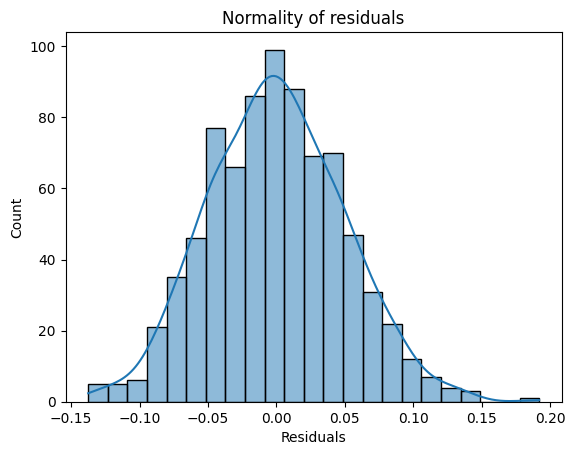

In [45]:
sns.histplot(data=df_pred, x="Residuals", kde=True)
plt.title("Normality of residuals")
plt.show()

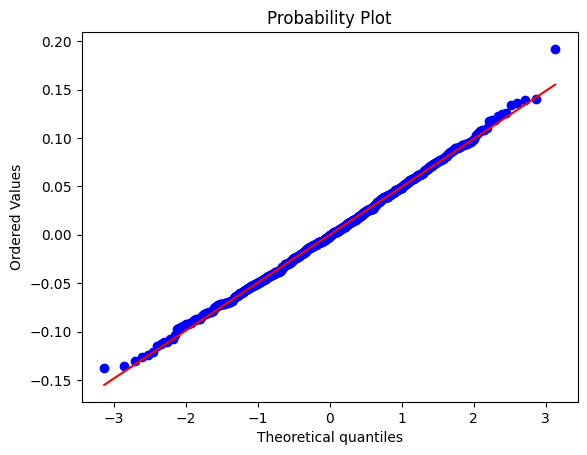

In [46]:
import scipy.stats as stats
import pylab
stats.probplot(df_pred["Residuals"], dist="norm", plot=pylab)
plt.show()

In [47]:
stats.shapiro(df_pred["Residuals"])

ShapiroResult(statistic=np.float64(0.9980675192349445), pvalue=np.float64(0.5050706693244453))


### **Test for Normality of Residuals**

**Objective:**
To check whether the residuals from our regression model are normally distributed, which is an important assumption for linear regression (especially for valid hypothesis testing and confidence intervals).

**Methods Used:**

1. **Histogram with KDE** – Plotted the distribution of residuals with a kernel density estimate.
2. **Q–Q Plot** – Compared the quantiles of the residuals with those of a theoretical normal distribution.
3. **Shapiro–Wilk Test** – A formal statistical test for normality.

**Results:**

* **Histogram:** The residuals form a symmetric bell-shaped distribution centered around zero, with no extreme skewness or kurtosis.
* **Q–Q Plot:** The residuals closely follow the diagonal line, indicating that their distribution is close to normal, with only minor deviations at the tails.
* **Shapiro–Wilk Test:**

  * Statistic = **0.9981**,
  * p-value = **0.5051**.
    Since p > 0.05, we fail to reject the null hypothesis of normality.

**Conclusion:**
The residuals are approximately normally distributed. This satisfies the normality assumption for the linear regression model.

TEST FOR HOMOSCEDASTICITY

We will test for homoscedasticity by using the goldfeldquandt test.
If we get a p-value greater than 0.05, we can say that the residuals are homoscedastic. Otherwise, they are heteroscedastic.

In [48]:
import statsmodels.stats.api as sms
from statsmodels.compat import lzip

name = ["F statistic", "p-value"]
test = sms.het_goldfeldquandt(df_pred["Residuals"], x_train2)
lzip(name, test)

[('F statistic', np.float64(1.025490628476713)),
 ('p-value', np.float64(0.4020425649699726))]

**Test for Homoscedasticity**

The Goldfeld–Quandt test was performed to check whether the variance of the residuals is constant across the range of fitted values (homoscedasticity). The test yielded an **F-statistic of 1.025** with a **p-value of 0.402**.

Since the p-value is greater than the 0.05 significance level, we fail to reject the null hypothesis of equal variances. This indicates that there is **no statistical evidence of heteroscedasticity**, and the assumption of homoscedasticity for linear regression is satisfied.


# **Model performance evaluation**

In [49]:
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np
import pandas as pd

# function to compute MAPE
def mape_score(targets, predictions):
    return np.mean(np.abs(targets - predictions) / targets) * 100

# function to compute different metrics to check performance of a regression model
def model_performance_regression(model, predictors, target):
    """
    Function to compute different metrics to check regression model performance

    model: regressor
    predictors: independent variables
    target: dependent variable
    """
    # predicting using the independent variables
    pred = model.predict(predictors)

    rmse = np.sqrt(mean_squared_error(target, pred))  # RMSE
    mae = mean_absolute_error(target, pred)          # MAE
    mape = mape_score(target, pred)                  # MAPE

    # creating a dataframe of metrics
    df_perf = pd.DataFrame(
        {
            "RMSE": [rmse],
            "MAE": [mae],
            "MAPE": [mape],
        }
    )

    return df_perf

# checking model performance on train set (seen 80% data)
print("Training Performance\n")
olsmodel2_train_perf = model_performance_regression(olsmodel2, x_train2, y_train)
display(olsmodel2_train_perf)

# checking model performance on test set (unseen 20% data)
olsmodel2_test_perf = model_performance_regression(olsmodel2, x_test2, y_test)
display(olsmodel2_test_perf)

Training Performance



,RMSE,MAE,MAPE
0,0.04937,0.039367,8.79069


,RMSE,MAE,MAPE
0,0.051235,0.040031,8.633445


### **Model Performance Evaluation**

To assess how well the regression model predicts the target variable, we calculated three key performance metrics on both the training (80%) and testing (20%) datasets:

1. **Root Mean Squared Error (RMSE):**
   Measures the square root of the average squared differences between predicted and actual values. It penalizes larger errors more heavily, making it sensitive to outliers. Lower values indicate better fit.

2. **Mean Absolute Error (MAE):**
   Measures the average absolute difference between predicted and actual values, providing a more intuitive understanding of typical prediction error in the same units as the target variable.

3. **Mean Absolute Percentage Error (MAPE):**
   Measures the average absolute percentage difference between predicted and actual values, giving an error rate in percentage terms.

The model performance was evaluated as follows:

* **Training Set:** Performance metrics were computed using the 80% of data used for model fitting.
* **Testing Set:** Metrics were computed on the remaining 20% of unseen data to evaluate generalization ability.

**Interpretation:**

The training and testing errors are very close across all metrics, suggesting that the model generalizes well to unseen data and does not suffer from significant overfitting or underfitting. The consistently low error values confirm that the model provides accurate and reliable predictions for the target variable.